In [146]:
import numpy as np
import matplotlib.pyplot as plt

# Number of moving particles
N = 32

# Physical parameters
m = 1.0
K = 1.0

# Nonlinear coefficients
alpha = 0.25
beta = 0.0

# Initial displacement amplitude
A = 1.0

# Numerical integration parameters
dt = 0.05
T_total = 40000

#simulation runs for 100 time units, with a timestep of 0.01
# Number of time steps
num_steps = int(T_total / dt)

# Printing the parameters
print("FPUT Simulation Parameters")
print("--------------------------")
print("Number of particles:", N)
print("Mass:", m)
print("Spring constant:", K)
print("Alpha:", alpha)
print("Beta:", beta)
print("Initial amplitude:", A)
print("Time step:", dt)
print("Total simulation time:", T_total)
print("Number of time steps:", num_steps)

FPUT Simulation Parameters
--------------------------
Number of particles: 32
Mass: 1.0
Spring constant: 1.0
Alpha: 0.25
Beta: 0.0
Initial amplitude: 1.0
Time step: 0.05
Total simulation time: 40000
Number of time steps: 800000


In [147]:
# Particle indices: 1, 2, ..., N
i = np.arange(1, N + 1)
MODE=1
# Initial displacement: first normal mode
x = A * np.sin(i * np.pi * MODE / (N + 1))

# Initial velocity: all particles start from rest
v = np.zeros(N)

# Display initial positions and velocities
print("Initial displacements:")
print(x)

print("\nInitial velocities:")
print(v)

Initial displacements:
[0.09505604 0.18925124 0.28173256 0.37166246 0.45822652 0.54064082
 0.61815899 0.69007901 0.75574957 0.81457595 0.8660254  0.909632
 0.94500082 0.97181157 0.98982144 0.99886734 0.99886734 0.98982144
 0.97181157 0.94500082 0.909632   0.8660254  0.81457595 0.75574957
 0.69007901 0.61815899 0.54064082 0.45822652 0.37166246 0.28173256
 0.18925124 0.09505604]

Initial velocities:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0.]


x_full =  [0.         0.09505604 0.18925124 0.28173256 0.37166246 0.45822652
 0.54064082 0.61815899 0.69007901 0.75574957 0.81457595 0.8660254
 0.909632   0.94500082 0.97181157 0.98982144 0.99886734 0.99886734
 0.98982144 0.97181157 0.94500082 0.909632   0.8660254  0.81457595
 0.75574957 0.69007901 0.61815899 0.54064082 0.45822652 0.37166246
 0.28173256 0.18925124 0.09505604 0.        ]


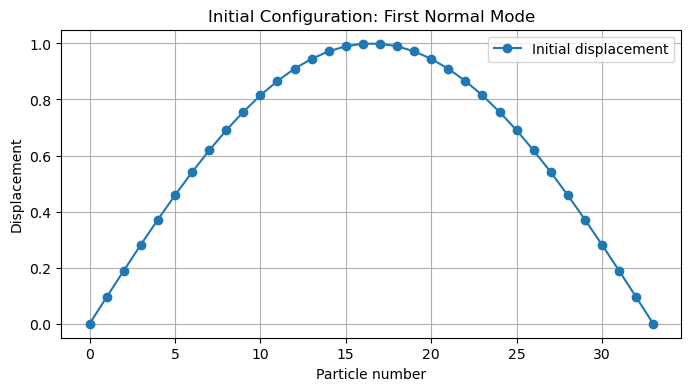

In [148]:

# Include the two fixed endpoints
x_full = np.zeros(N + 2)

# Insert the displacements of the moving particles
x_full[1:N+1] = x

# Particle indices including fixed endpoints
particle_indices = np.arange(0, N + 2)

print("x_full = ", x_full) #initial displacements of [0,N+1] particles

# Plot the initial configuration
plt.figure(figsize=(8, 4))

plt.plot(particle_indices, x_full, 'o-', label='Initial displacement')

plt.xlabel('Particle number')
plt.ylabel('Displacement')
plt.title('Initial Configuration: First Normal Mode')

plt.grid(True)
plt.legend()
plt.show()


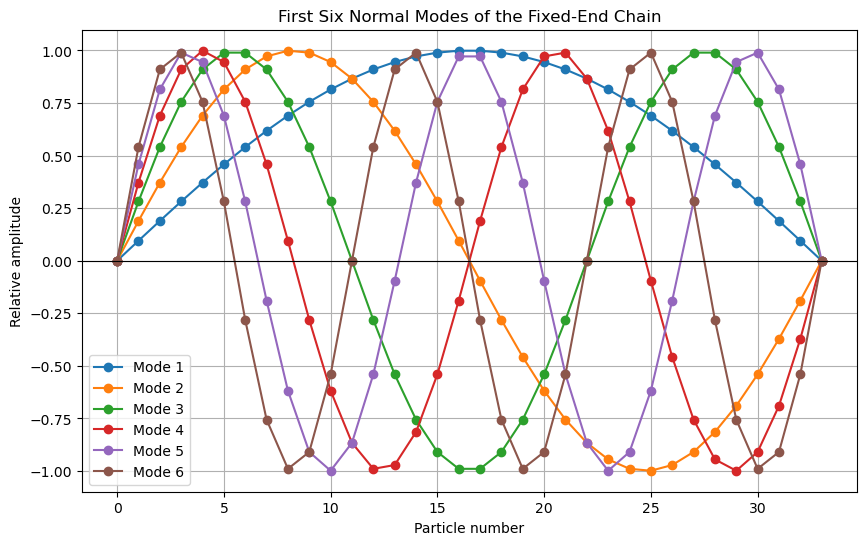

In [149]:

# Plotting the first six normal modes

plt.figure(figsize=(10, 6))

# Include the two fixed endpoints
particle_indices = np.arange(0, N + 2)

for k in range(1, 7):

    # Calculating the shape of the kth normal mode
    mode_shape = np.sin(
        particle_indices * k * np.pi / (N + 1)
    )

    plt.plot(
        particle_indices,
        mode_shape,
        marker='o',
        label=f'Mode {k}'
    )

plt.xlabel('Particle number')
plt.ylabel('Relative amplitude')
plt.title('First Six Normal Modes of the Fixed-End Chain')

plt.grid(True)
plt.legend()
plt.axhline(0, color='black', linewidth=0.8)
plt.show()


In [150]:

def calculate_spring_extensions(x):
    """
    Calculate the extensions of all springs.

    x contains the displacements of the N moving particles.
    The two fixed endpoints have zero displacement.
    """

    # Create an array including the fixed endpoints
    x_full = np.zeros(N + 2)

    # Insert the moving particle displacements
    x_full[1:N+1] = x

    # Difference between neighboring positions
    extensions = np.diff(x_full)

    return extensions


# Calculate extensions for our initial configuration
r = calculate_spring_extensions(x)

print("Number of springs:", len(r))
print("Spring extensions:")
print(r)

print("Maximum absolute extension:", np.max(np.abs(r)))


Number of springs: 33
Spring extensions:
[ 0.09505604  0.0941952   0.09248131  0.0899299   0.08656407  0.0824143
  0.07751817  0.07192003  0.06567056  0.05882638  0.05144945  0.04360659
  0.03536882  0.02681075  0.01800987  0.0090459   0.         -0.0090459
 -0.01800987 -0.02681075 -0.03536882 -0.04360659 -0.05144945 -0.05882638
 -0.06567056 -0.07192003 -0.07751817 -0.0824143  -0.08656407 -0.0899299
 -0.09248131 -0.0941952  -0.09505604]
Maximum absolute extension: 0.09505604330418288


In [151]:

def calculate_potential_energy(x, alpha, beta):
    """
    Calculate the total potential energy of the chain.
    """
    # Calculate all spring extensions
    extensions = calculate_spring_extensions(x)
    
    # Harmonic contribution
    harmonic_energy = 0.5 * K * np.sum(extensions**2)

    # Cubic contribution
    alpha_energy = (alpha / 3.0) * np.sum(extensions**3)

    # Quartic contribution
    beta_energy = (beta / 4.0) * np.sum(extensions**4)

    # Total potential energy
    total_potential_energy = (
        harmonic_energy
        + alpha_energy
        + beta_energy
    )

    return total_potential_energy


# Calculate the initial potential energy
U_initial = calculate_potential_energy(x, alpha, beta)

print("Initial potential energy:", U_initial)


Initial potential energy: 0.07471327754410403


In [152]:

def calculate_force(x, alpha, beta):
    """
    Calculate the force acting on every moving particle.
    """

    # Calculate spring extensions
    extensions = calculate_spring_extensions(x)

    # Extensions of the springs to the left and right
    left_extensions = extensions[:-1]
    right_extensions = extensions[1:]

    # Harmonic force
    harmonic_force = K * (
        right_extensions - left_extensions
    )

    # Cubic nonlinear force
    alpha_force = alpha * (
        right_extensions**2 - left_extensions**2
    )

    # Quartic nonlinear force
    beta_force = beta * (
        right_extensions**3 - left_extensions**3
    )

    # Total force
    force = harmonic_force + alpha_force + beta_force

    return force


# Calculate the initial force
initial_force = calculate_force(x, alpha, beta)

print("Initial force on each particle:")
print(initial_force)

print("Number of force values:", len(initial_force))


Initial force on each particle:
[-0.00090157 -0.00179387 -0.00266777 -0.00351435 -0.00432508 -0.00509189
 -0.00580729 -0.00646443 -0.00705721 -0.0075803  -0.00802924 -0.00840041
 -0.00869111 -0.00889949 -0.00902461 -0.00906635 -0.00902544 -0.00890334
 -0.00870226 -0.00842504 -0.00807512 -0.00765648 -0.00717355 -0.00663117
 -0.0060345  -0.005389   -0.00470036 -0.00397446 -0.00321732 -0.00243506
 -0.0016339  -0.00082011]
Number of force values: 32


In [153]:

def calculate_acceleration(x, alpha, beta):
    """
    Calculate the acceleration of every moving particle.
    """

    force = calculate_force(x, alpha, beta)

    acceleration = force / m

    return acceleration


# Calculate initial acceleration
initial_acceleration = calculate_acceleration(x, alpha, beta)

print("Initial acceleration:")
print(initial_acceleration)


Initial acceleration:
[-0.00090157 -0.00179387 -0.00266777 -0.00351435 -0.00432508 -0.00509189
 -0.00580729 -0.00646443 -0.00705721 -0.0075803  -0.00802924 -0.00840041
 -0.00869111 -0.00889949 -0.00902461 -0.00906635 -0.00902544 -0.00890334
 -0.00870226 -0.00842504 -0.00807512 -0.00765648 -0.00717355 -0.00663117
 -0.0060345  -0.005389   -0.00470036 -0.00397446 -0.00321732 -0.00243506
 -0.0016339  -0.00082011]


In [154]:

# Small displacement for finite differences
epsilon = 1e-6

# Calculate analytical force
force_analytical = calculate_force(x, alpha, beta)

# Array to store numerical force
force_numerical = np.zeros(N)

# Calculate numerical force for each particle
for j in range(N):

    # Copy the original displacement array
    x_plus = x.copy()
    x_minus = x.copy()

    # Slightly increase and decrease one displacement
    x_plus[j] += epsilon
    x_minus[j] -= epsilon

    # Calculate potential energies
    U_plus = calculate_potential_energy(x_plus, alpha, beta)
    U_minus = calculate_potential_energy(x_minus, alpha, beta)

    # Negative central finite difference
    force_numerical[j] = -(U_plus - U_minus) / (2 * epsilon)


# Compare the two force calculations
force_error = np.max(
    np.abs(force_analytical - force_numerical)
)

print("Maximum force difference:", force_error)


Maximum force difference: 9.930962302506785e-12


In [155]:

def calculate_kinetic_energy(v):
    """
    Calculate the total kinetic energy of the moving particles.
    """

    kinetic_energy = 0.5 * m * np.sum(v**2)

    return kinetic_energy


def calculate_total_energy(x, v, alpha, beta):
    """
    Calculate the total Hamiltonian of the FPUT chain.
    """

    kinetic_energy = calculate_kinetic_energy(v)

    potential_energy = calculate_potential_energy(
        x, alpha, beta
    )

    total_energy = kinetic_energy + potential_energy

    return total_energy


# Calculate the initial energies
T_initial = calculate_kinetic_energy(v)
U_initial = calculate_potential_energy(x, alpha, beta)
H_initial = calculate_total_energy(x, v, alpha, beta)

print("Initial kinetic energy:", T_initial)
print("Initial potential energy:", U_initial)
print("Initial total energy:", H_initial)


Initial kinetic energy: 0.0
Initial potential energy: 0.07471327754410403
Initial total energy: 0.07471327754410403


In [156]:
#Velocity-Verlet Algorithm function
def simulate(alpha, beta, dt, total_time, save_every):
    """
    Simulate the FPUT chain using the Velocity Verlet method.

    Parameters:
        alpha      : Cubic nonlinear coefficient
        beta       : Quartic nonlinear coefficient
        dt         : Time step
        total_time : Total simulation duration
        save_every : Save results after this many steps
    """

    # Number of integration steps
    num_steps = int(total_time / dt)

    # Start from the initial conditions
    x_current = x.copy()
    v_current = v.copy()

    # Calculate initial acceleration
    a_current = calculate_acceleration(
        x_current, alpha, beta
    )

    # Lists to store simulation results
    time_values = []
    position_values = []
    velocity_values = []
    energy_values = []

    # Save the initial state
    time_values.append(0.0)
    position_values.append(x_current.copy())
    velocity_values.append(v_current.copy())

    energy = calculate_total_energy(
        x_current, v_current, alpha, beta
    )
    energy_values.append(energy)

    # Perform Velocity Verlet integration
    for step in range(1, num_steps + 1):

        # Step 1: Update velocity by half a time step
        v_half = v_current + 0.5 * dt * a_current

        # Step 2: Update position
        x_new = x_current + dt * v_half

        # Step 3: Calculate acceleration at new position
        a_new = calculate_acceleration(
            x_new, alpha, beta
        )

        # Step 4: Complete the velocity update
        v_new = v_half + 0.5 * dt * a_new

        # Update current position, velocity and acceleration
        x_current = x_new
        v_current = v_new
        a_current = a_new

        # Save results at selected intervals
        if step % save_every == 0 or step == num_steps:

            current_time = step * dt

            time_values.append(current_time)
            position_values.append(x_current.copy())
            velocity_values.append(v_current.copy())

            energy = calculate_total_energy(
                x_current, v_current, alpha, beta
            )
            energy_values.append(energy)

    # Convert lists into NumPy arrays
    time_values = np.array(time_values)
    position_values = np.array(position_values)
    velocity_values = np.array(velocity_values)
    energy_values = np.array(energy_values)

    return time_values, position_values, velocity_values, energy_values


In [157]:

# Run the FPUT-alpha simulation
time_values, position_values, velocity_values, energy_values = simulate(
    alpha=0.25,
    beta=0.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

# Display the simulation information
print("Simulation completed")
print("---------------------")

print("Number of saved time points:", len(time_values))
print("Position array shape:", position_values.shape)
print("Velocity array shape:", velocity_values.shape)
print("Energy array shape:", energy_values.shape)

print("Initial energy:", energy_values[0])
print("Final energy:", energy_values[-1])

# Calculate relative energy drift
relative_energy_error = (
    energy_values - energy_values[0]
) / energy_values[0]


print(
    "Maximum absolute relative energy drift:",
    np.max(np.abs(relative_energy_error))
)


Simulation completed
---------------------
Number of saved time points: 2001
Position array shape: (2001, 32)
Velocity array shape: (2001, 32)
Energy array shape: (2001,)
Initial energy: 0.07471327754410403
Final energy: 0.07471308394689063
Maximum absolute relative energy drift: 3.5138596188914705e-05


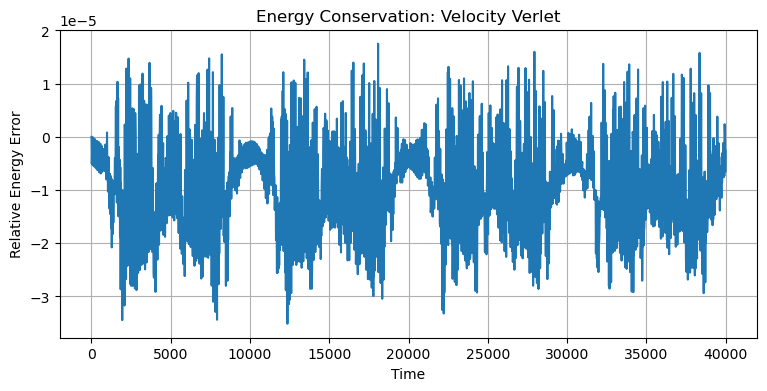

In [158]:

plt.figure(figsize=(9, 4))

plt.plot(time_values, relative_energy_error)

plt.xlabel("Time")
plt.ylabel("Relative Energy Error")
plt.title("Energy Conservation: Velocity Verlet")

plt.grid(True)
plt.show()


In [159]:
particle_indices = np.arange(1, N + 1)
mode_indices = np.arange(1, N + 1)

Phi = np.sqrt(2.0 / (N + 1)) * np.sin(
    np.outer(particle_indices, mode_indices) * np.pi / (N + 1)
)

omega = 2.0 * np.sqrt(K / m) * np.sin(
    mode_indices * np.pi / (2 * (N + 1))
)

In [160]:
Q = position_values @ Phi
Q_dot = velocity_values @ Phi

In [161]:
modal_energy = 0.5 * m * Q_dot**2 + 0.5 * m * omega**2 * Q**2

In [162]:
modal_fraction = modal_energy / np.sum(modal_energy, axis=1, keepdims=True)

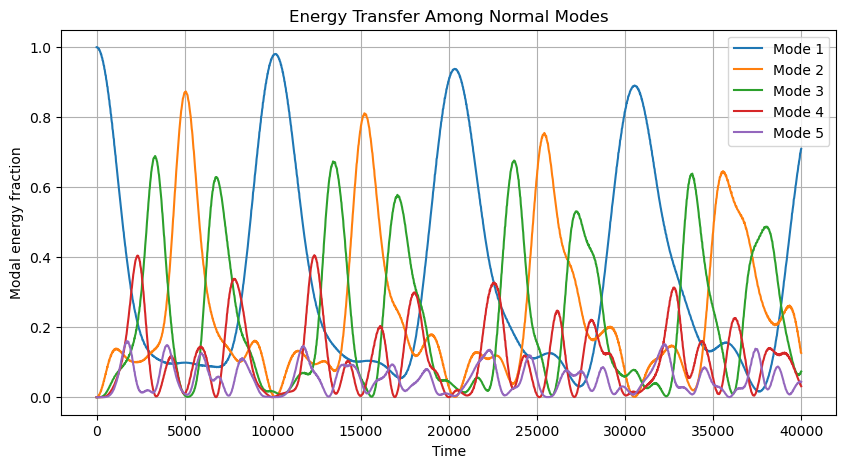

In [163]:
plt.figure(figsize=(10, 5))

for k in range(5):
    plt.plot(time_values, modal_fraction[:, k], label=f"Mode {k+1}")

plt.xlabel("Time")
plt.ylabel("Modal energy fraction")
plt.title("Energy Transfer Among Normal Modes")
plt.legend()
plt.grid(True)
plt.show()

In [164]:
identity = np.eye(N)
orthogonality_error = np.max(np.abs(Phi.T @ Phi - identity))

print("Orthonormality error:", orthogonality_error)

Orthonormality error: 2.220446049250313e-15


In [165]:
initial_mode_energy = modal_energy[0]
initial_mode_fraction = modal_fraction[0]

print("Initial modal energy fractions:")
for k in range(5):
    print(f"Mode {k+1}: {initial_mode_fraction[k]:.6f}")

Initial modal energy fractions:
Mode 1: 1.000000
Mode 2: 0.000000
Mode 3: 0.000000
Mode 4: 0.000000
Mode 5: 0.000000


In [166]:
linear_time, linear_x, linear_v, linear_energy = simulate(
    alpha=0.0,
    beta=0.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

alpha_time, alpha_x, alpha_v, alpha_energy = simulate(
    alpha=0.25,
    beta=0.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

In [167]:
linear_Q = linear_x @ Phi
linear_Q_dot = linear_v @ Phi

alpha_Q = alpha_x @ Phi
alpha_Q_dot = alpha_v @ Phi

linear_modal_energy = (
    0.5 * m * linear_Q_dot**2
    + 0.5 * m * omega**2 * linear_Q**2
)

alpha_modal_energy = (
    0.5 * m * alpha_Q_dot**2
    + 0.5 * m * omega**2 * alpha_Q**2
)

linear_fraction = linear_modal_energy / np.sum(
    linear_modal_energy, axis=1, keepdims=True
)

alpha_fraction = alpha_modal_energy / np.sum(
    alpha_modal_energy, axis=1, keepdims=True
)

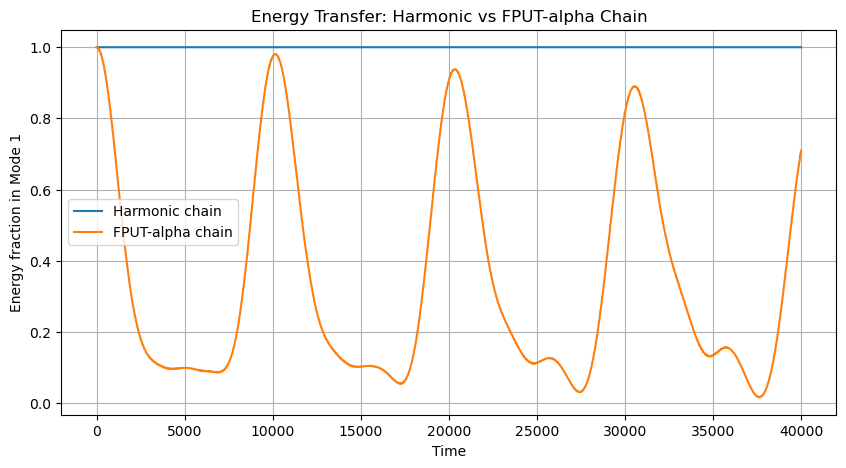

In [168]:
plt.figure(figsize=(10, 5))

plt.plot(linear_time, linear_fraction[:, 0],
         label="Harmonic chain")

plt.plot(alpha_time, alpha_fraction[:, 0],
         label="FPUT-alpha chain")

plt.xlabel("Time")
plt.ylabel("Energy fraction in Mode 1")
plt.title("Energy Transfer: Harmonic vs FPUT-alpha Chain")
plt.legend()
plt.grid(True)
plt.show()

In [169]:
spectral_entropy = -np.sum(
    np.where(
        alpha_fraction > 0,
        alpha_fraction * np.log(np.maximum(alpha_fraction, 1e-15)),
        0
    ),
    axis=1
)

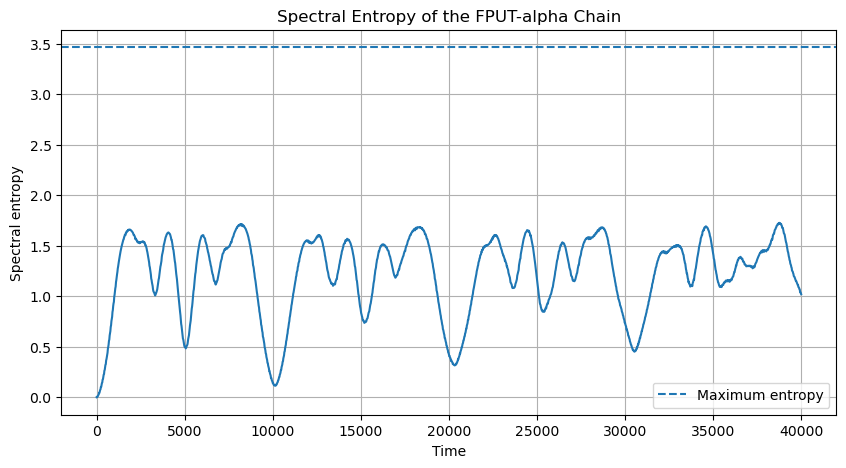

In [170]:
plt.figure(figsize=(10, 5))

plt.plot(alpha_time, spectral_entropy)

plt.axhline(np.log(N), linestyle="--",
            label="Maximum entropy")

plt.xlabel("Time")
plt.ylabel("Spectral entropy")
plt.title("Spectral Entropy of the FPUT-alpha Chain")
plt.legend()
plt.grid(True)
plt.show()

In [171]:
alpha_run = simulate(
    alpha=0.25,
    beta=0.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

beta_run = simulate(
    alpha=0.0,
    beta=5.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

combined_run = simulate(
    alpha=0.25,
    beta=5.0,
    dt=dt,
    total_time=T_total,
    save_every=400
)

In [172]:
def get_modal_fractions(position_data, velocity_data):
    Q = position_data @ Phi
    Q_dot = velocity_data @ Phi

    E = 0.5 * m * Q_dot**2 + 0.5 * m * omega**2 * Q**2
    fractions = E / np.sum(E, axis=1, keepdims=True)

    return fractions

In [173]:
alpha_fraction = get_modal_fractions(alpha_run[1], alpha_run[2])
beta_fraction = get_modal_fractions(beta_run[1], beta_run[2])
combined_fraction = get_modal_fractions(combined_run[1], combined_run[2])

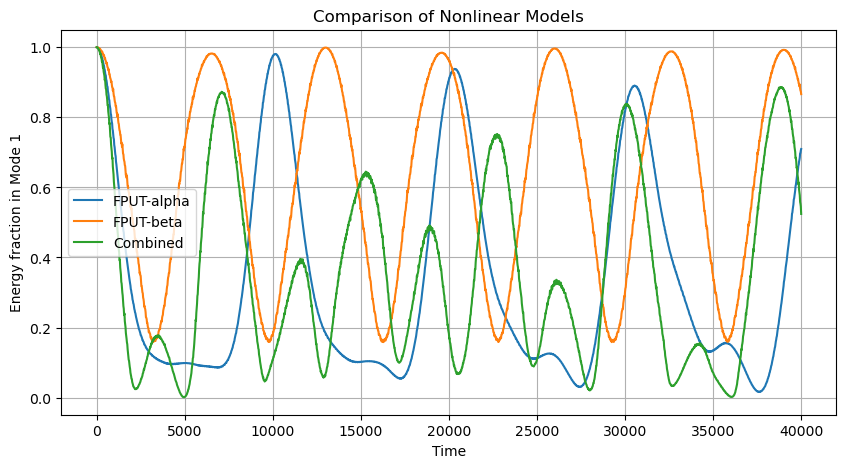

In [174]:
plt.figure(figsize=(10, 5))

plt.plot(alpha_run[0], alpha_fraction[:, 0], label="FPUT-alpha")
plt.plot(beta_run[0], beta_fraction[:, 0], label="FPUT-beta")
plt.plot(combined_run[0], combined_fraction[:, 0], label="Combined")

plt.xlabel("Time")
plt.ylabel("Energy fraction in Mode 1")
plt.title("Comparison of Nonlinear Models")
plt.legend()
plt.grid(True)
plt.show()

In [175]:
def calculate_entropy(fractions):
    return -np.sum(
        np.where(
            fractions > 0,
            fractions * np.log(np.maximum(fractions, 1e-15)),
            0
        ),
        axis=1
    )

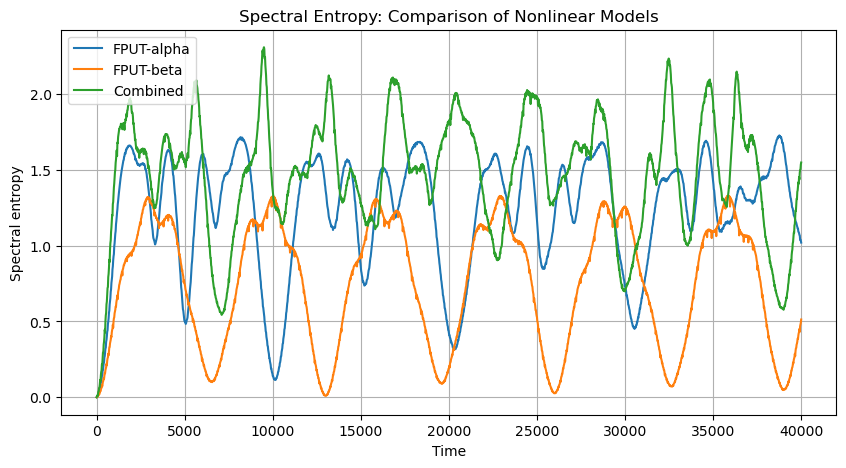

In [176]:
S_alpha = calculate_entropy(alpha_fraction)
S_beta = calculate_entropy(beta_fraction)
S_combined = calculate_entropy(combined_fraction)

plt.figure(figsize=(10, 5))

plt.plot(alpha_run[0], S_alpha, label="FPUT-alpha")
plt.plot(beta_run[0], S_beta, label="FPUT-beta")
plt.plot(combined_run[0], S_combined, label="Combined")

plt.xlabel("Time")
plt.ylabel("Spectral entropy")
plt.title("Spectral Entropy: Comparison of Nonlinear Models")
plt.legend()
plt.grid(True)
plt.show()